In [1]:

print("Hello! My first EDA project")

Hello! My first EDA project


In [2]:

import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450

In [3]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check all column names
print("\nColumn names:")
print(df.columns.tolist())

# Get basic information about the dataset
print("\nDataset information:")
df.info()

# Get basic statistics
print("\nStatistical summary:")
print(df.describe())

Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical summary:
       PassengerId    Survived      Pclass 

In [4]:

# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Calculate missing value percentages
print("\nMissing value percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing value percentage:
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

Duplicate rows: 0


In [5]:

# Create a separate copy for cleaning
clean_df = df.copy()

# Fill missing Age values with the median age
clean_df["Age"] = clean_df["Age"].fillna(
    clean_df["Age"].median()
)

# Fill missing Embarked values with the most common value
clean_df["Embarked"] = clean_df["Embarked"].fillna(
    clean_df["Embarked"].mode()[0]
)

# Drop Cabin because 77.10% of its values are missing
clean_df = clean_df.drop(columns=["Cabin"])

# Check the result
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

print("\nCleaned dataset shape:", clean_df.shape)


Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Cleaned dataset shape: (891, 11)


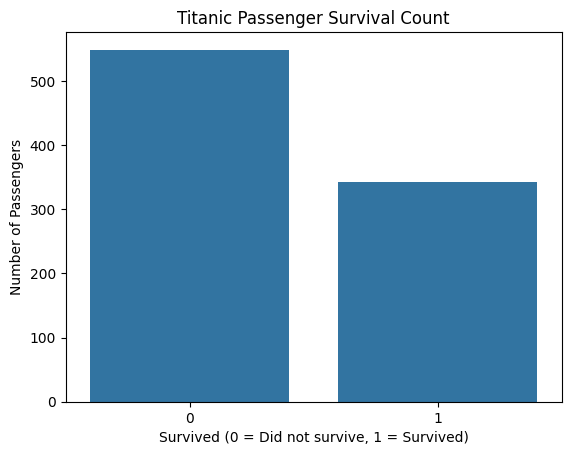

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=clean_df, x="Survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = Did not survive, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.savefig("survival_count.png", dpi=300, bbox_inches="tight")
plt.show()

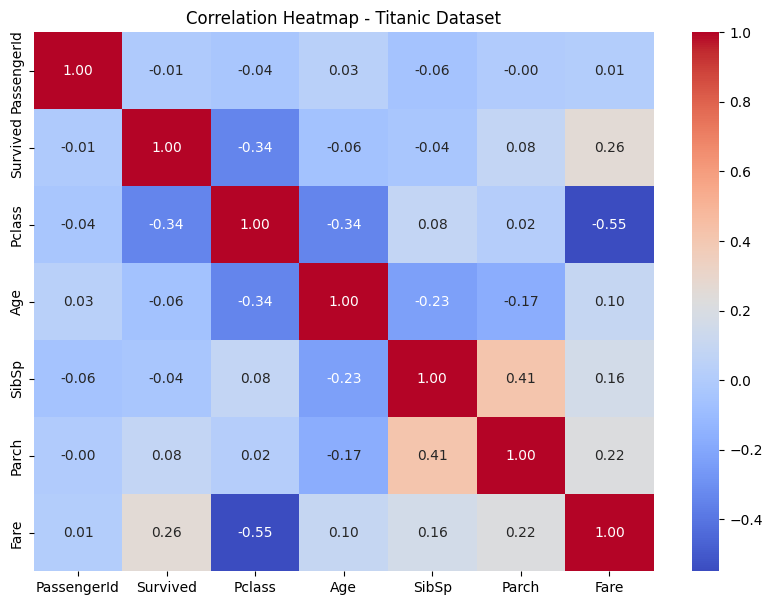

In [7]:

# Select only numerical columns
numeric_df = clean_df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Draw the heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Titanic Dataset")
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

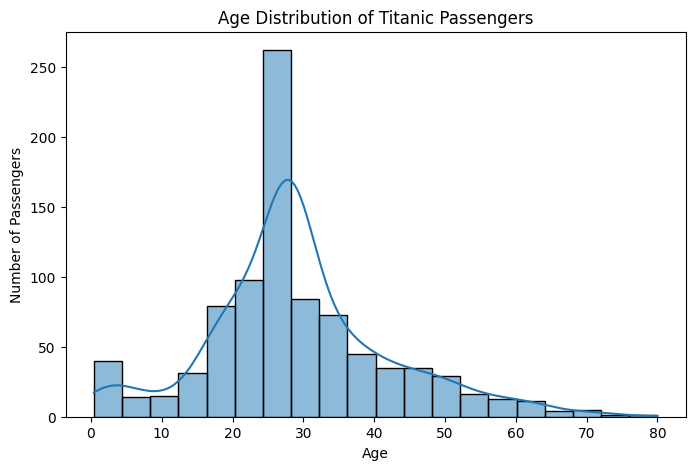

In [8]:

plt.figure(figsize=(8, 5))

sns.histplot(data=clean_df, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.savefig("age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

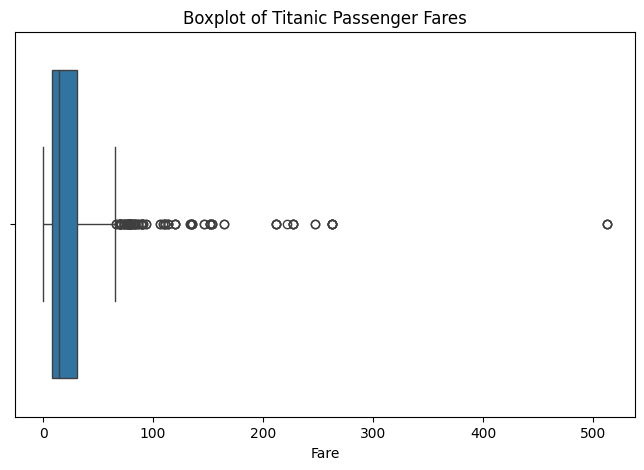

In [9]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=clean_df, x="Fare")

plt.title("Boxplot of Titanic Passenger Fares")
plt.xlabel("Fare")

plt.savefig("fare_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

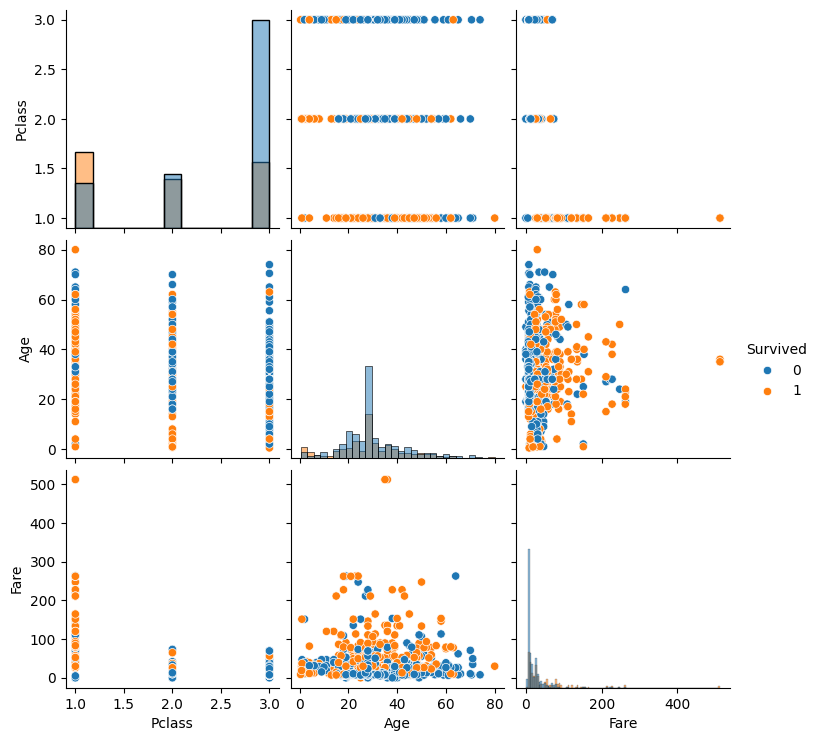

In [10]:

# Select important numerical columns
pair_df = clean_df[["Survived", "Pclass", "Age", "Fare"]]

# Create pairwise plots
sns.pairplot(
    pair_df,
    hue="Survived",
    diag_kind="hist"
)

plt.savefig("pairwise_scatter_plots.png", dpi=300, bbox_inches="tight")
plt.show()

# Exploratory Data Analysis of the Titanic Dataset

## 1. Project Overview

This project performs Exploratory Data Analysis (EDA) on the Titanic passenger dataset using Python. The objective is to understand the data, handle missing values, identify potential outliers, and discover patterns using visualizations.

## 2. Dataset Information

* Total rows: 891
* Original columns: 12
* Columns after cleaning: 11
* Target column: Survived
* Libraries used: Pandas, NumPy, Matplotlib, Seaborn

## 3. Data Cleaning

* Checked missing values in every column.
* Checked duplicate rows; none were found.
* Filled missing Age values using the median.
* Filled missing Embarked values using the mode.
* Removed Cabin because approximately 77.10% of its values were missing.
* Preserved the original dataset by cleaning a separate copy.

## 4. Visualizations

1. Survival Count Plot: Compares the number of survivors and non-survivors.
2. Correlation Heatmap: Displays correlations among numerical variables.
3. Age Distribution: Shows how passenger ages are distributed.
4. Fare Boxplot: Helps identify potential fare outliers.
5. Pairplot: Compares numerical features and shows patterns by survival status.

## 5. Conclusion

EDA helped reveal the structure and quality of the Titanic dataset. Data cleaning addressed missing values in selected columns, and visualizations helped explore passenger survival, age distribution, fare variation, and relationships between numerical features. These findings can support further statistical analysis and machine learning.


In [11]:

import os
import zipfile
from google.colab import files

graph_files = [
    "survival_count.png",
    "correlation_heatmap.png",
    "age_distribution.png",
    "fare_boxplot.png",
    "pairwise_scatter_plots.png"
]

with zipfile.ZipFile("visualizations.zip", "w") as zipf:
    for file in graph_files:
        if os.path.exists(file):
            zipf.write(file)
            print("Added:", file)
        else:
            print("Missing:", file)

files.download("visualizations.zip")

Added: survival_count.png
Added: correlation_heatmap.png
Added: age_distribution.png
Added: fare_boxplot.png
Added: pairwise_scatter_plots.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Observations and Findings

### 1. Survival Count

Approximately 38.4% of passengers survived, while 61.6% did not survive. This shows that more passengers died than survived.

### 2. Correlation Heatmap

The heatmap helps identify relationships between numerical features. Passenger class and fare show a negative correlation, while survival and passenger class also show a negative correlation.

### 3. Age Distribution

The age distribution shows that passengers came from different age groups, with many passengers in the young-adult and adult ranges.

### 4. Fare Boxplot and Outliers

The boxplot shows unusually high fare values compared with most passengers. These values may be outliers, but they may also represent genuine ticket prices. Therefore, I retained them rather than removing potentially valid data without further investigation.

### 5. Pairwise Scatter Plots

The scatter plots help compare age, fare, passenger class, and survival. They allow us to observe patterns and differences between passengers who survived and those who did not.

## Conclusion

The EDA process helped identify missing values, check for duplicate records, clean the dataset, and understand patterns through visualizations. The analysis suggests that passenger characteristics are useful for exploring survival patterns, although correlation alone does not prove causation.
